## 2. Complex vectors

### 2.1 Definition

A <span style="color:red">**complex vector** is an ordered list of $n$ complex numbers</span> :

$$v = \begin{pmatrix} v_1 \\ \vdots \\ v_n \end{pmatrix}\in\mathbb{C}^n, \qquad v_i = r_i e^{i\theta_i}$$

- Add component-wise; scale by a **complex** scalar $c$: $cv=(cv_1,\dots,cv_n)$.
- The components $v_i$ are called **amplitudes**: $\lvert v_i\rvert$ is the "how much" (its square will be a probability) and $\arg v_i$ is the phase.
- It carries $2n$ real numbers: $n$ lengths and $n$ angles.
- <span style="color:red">**A qubit is a complex vector**</span> in $\mathbb{C}^2$ with $\lvert v_1\rvert^2+\lvert v_2\rvert^2=1$; $n$ qubits give $\mathbb{C}^{2^n}$.

### 2.2 Global phase vs. relative phase

Multiply the whole vector by $e^{i\gamma}$ and **every** component rotates by the same angle — a **global phase**. The vector looks different but all lengths (hence all probabilities) are identical; it is physically unobservable.

Change the angle of **one** component only and you get a **relative phase** — a genuinely different state that interferes differently with others.

### 2.3 Visualization

A vector in $\mathbb{C}^2$ has 4 real dimensions, so draw **one arrow per component**, each in its own complex plane.

NameError: name 'complex_plane' is not defined

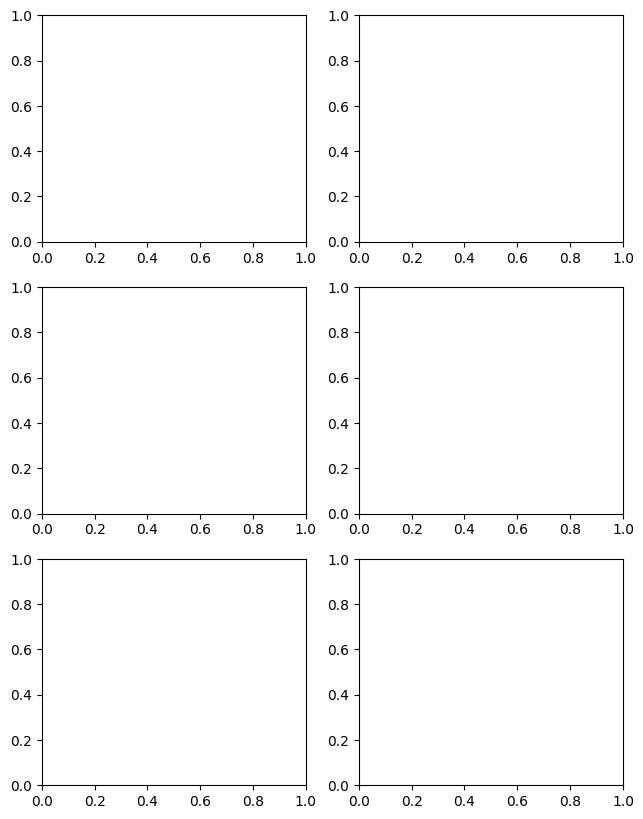

In [9]:
psi = np.array([1 / np.sqrt(2), 1j / np.sqrt(2)])                       # a vector in C^2
glob = np.exp(1j * 0.9) * psi                                           # global phase: both arrows rotate together
rel  = np.array([psi[0], psi[1] * np.exp(1j * 0.9)])                    # relative phase: only component 1 rotates

fig, axs = plt.subplots(3, 2, figsize=(7.5, 10))
rows = [("ψ", psi), ("e^{iγ}ψ   (global phase)", glob), ("relative phase on ψ₁", rel)]
for r, (name, v) in enumerate(rows):
    complex_plane(axs[r, 0], [("ψ₀", v[0], "tab:blue")], f"{name}: component 0")
    complex_plane(axs[r, 1], [("ψ₁", v[1], "tab:green")], f"{name}: component 1")
plt.tight_layout(); plt.show()

for name, v in rows:
    print(f"{name:28s} probabilities = {np.abs(v) ** 2}   sum = {np.sum(np.abs(v) ** 2):.3f}")

### 2.4 Example for an ML engineer — the Fourier transform is a complex vector

`np.fft.fft(signal)` returns a **complex vector**: the magnitudes are the "how much" of each frequency, the phases are the "where it sits in time". Shifting a signal in time changes **only the phases** — the magnitude spectrum (what a power-spectrum feature sees) is unchanged. That is the same split as in a qubit: magnitudes are observable, phases are hidden until things interfere.

magnitudes equal : True
phases equal     : False


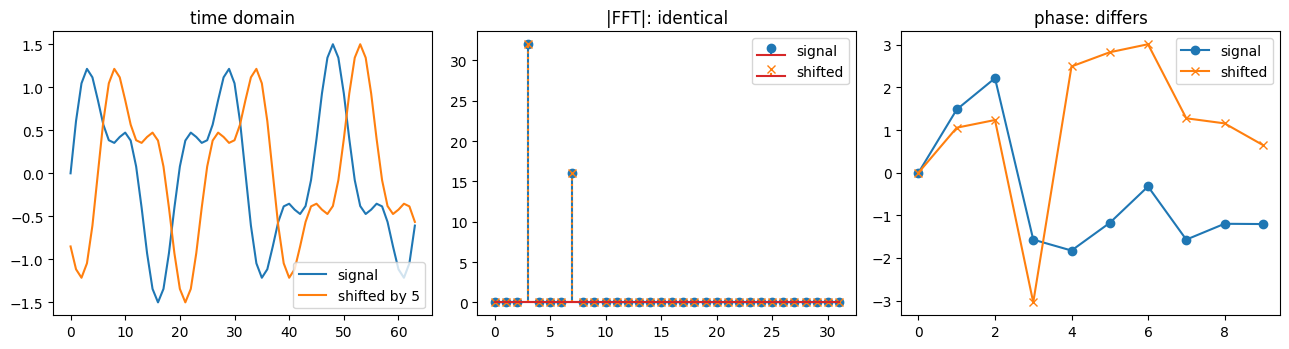

In [10]:
n = 64
tt = np.arange(n)
signal = np.sin(2 * np.pi * 3 * tt / n) + 0.5 * np.sin(2 * np.pi * 7 * tt / n)
shifted = np.roll(signal, 5)

F, Fs = np.fft.fft(signal)[:n // 2], np.fft.fft(shifted)[:n // 2]
print("magnitudes equal :", np.allclose(np.abs(F), np.abs(Fs)))
print("phases equal     :", np.allclose(np.angle(F[3]), np.angle(Fs[3])))

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
axs[0].plot(signal, label="signal"); axs[0].plot(shifted, label="shifted by 5"); axs[0].legend(); axs[0].set_title("time domain")
axs[1].stem(np.abs(F), markerfmt="C0o", label="signal"); axs[1].stem(np.abs(Fs), markerfmt="C1x", linefmt="C1:", label="shifted")
axs[1].set_title("|FFT|: identical"); axs[1].legend()
axs[2].plot(np.angle(F[:10]), "o-", label="signal"); axs[2].plot(np.angle(Fs[:10]), "x-", label="shifted")
axs[2].set_title("phase: differs"); axs[2].legend()
plt.tight_layout(); plt.show()

---
## 3. Vector spaces and Hilbert spaces

### 3.1 From a vector to a space

A **complex vector space** is the *collection* of all complex vectors of a given size, closed under the two operations:

- **add** any two vectors → still in the space;
- **scale** by any complex number → still in the space.

Adding two states with complex weights is a **superposition**: $\alpha|0\rangle+\beta|1\rangle$. "Superposition" is nothing more than "linear combination in a complex vector space".

A **Hilbert space** $\mathcal{H}$ is a complex vector space that also has

1. an **inner product** $\langle u, v\rangle=\sum_i\overline{u_i}\,v_i$ — lets you measure lengths, angles and overlaps (details in section 4), and
2. **completeness** — no "holes" (limits of sequences stay inside). In finite dimensions this is automatic.

So for qubits: **Hilbert space = $\mathbb{C}^n$ with the inner product above.**

| System | Hilbert space | Dimension |
|---|---|---|
| 1 qubit | $\mathbb{C}^2$ | 2 |
| 2 qubits | $\mathbb{C}^4$ | 4 |
| $n$ qubits | $\mathbb{C}^{2^n}$ | $2^n$ |

> **Why this matters.** The state of a quantum system *is* a unit vector in a Hilbert space. Everything else — gates, measurement, entanglement — is a statement about this space.


### 3.2 Properties and dimensionality

**Vector-space properties.** Complex vectors obey the same rules as real ones, with scalars taken from $\mathbb{C}$:

| Property | Statement |
|---|---|
| Closure | $u+v\in\mathcal{H}$ and $c\,v\in\mathcal{H}$ for every complex $c$ |
| Zero and inverses | $0\in\mathcal{H}$; every $v$ has $-v$ |
| Linearity | $c(u+v)=cu+cv$, $(c+d)v=cv+dv$, $c(dv)=(cd)v$ |
| Linear combination (superposition) | $\alpha u+\beta v$ with complex weights |
| Linear independence | no vector is a combination of the others |
| Subspace | a subset closed under the two operations, e.g. $\mathrm{span}\{\lvert00\rangle,\lvert11\rangle\}$ |

**Dimension** is the number of vectors in any basis. $\mathbb{C}^n$ has **complex dimension $n$** (equivalently $2n$ real dimensions). So $n$ qubits need $\mathbb{C}^{2^n}$.

**Counting real degrees of freedom of a state.** An $n$-dimensional complex vector has $2n$ real numbers. A *physical state* is a unit vector (**−1** for normalization) defined up to a global phase (**−1**). That leaves $2n-2$ real parameters:

| System | Complex dim $n$ | Real parameters of a state |
|---|---|---|
| 1 qubit | 2 | $2\cdot2-2=2$  → the two angles of the **Bloch sphere** |
| 2 qubits | 4 | $2\cdot4-2=6$ |
| $k$ qubits | $2^k$ | $2^{k+1}-2$ |

**Hilbert-space extras.** A Hilbert space also carries an inner product (next section) with $\langle u|v\rangle=\overline{\langle v|u\rangle}$, linear in the second slot, and $\langle v|v\rangle>0$ for $v\ne0$; and it is **complete**, which is automatic in finite dimensions.

In [11]:
rng_ = np.random.default_rng(3)
u = rng_.normal(size=4) + 1j * rng_.normal(size=4)
v = rng_.normal(size=4) + 1j * rng_.normal(size=4)
a, b = 0.3 + 0.4j, -0.2 + 0.9j

w = a * u + b * v                                   # closure: a superposition is still a vector in C^4
print("closure OK, w =", w)

# dimension = number of linearly independent vectors = matrix rank
basis4 = np.eye(4, dtype=complex)
print("rank of 4 random vectors in C^4 :", np.linalg.matrix_rank(np.column_stack([u, v, rng_.normal(size=4) + 0j, rng_.normal(size=4) * 1j])))
print("rank of {u, v, 2u+3v}            :", np.linalg.matrix_rank(np.column_stack([u, v, 2 * u + 3 * v])), " (third vector is dependent -> dimension of span = 2)")

# real parameters of a quantum state of dimension n
for k in (1, 2, 3):
    n_ = 2 ** k
    print(f"{k} qubit(s): C^{n_} -> {2 * n_} real numbers - 1 (norm) - 1 (global phase) = {2 * n_ - 2}")

closure OK, w = [ 1.2195-0.0419j -0.7438+2.0374j  1.8379-0.0245j  0.3447-0.5359j]
rank of 4 random vectors in C^4 : 4
rank of {u, v, 2u+3v}            : 2  (third vector is dependent -> dimension of span = 2)
1 qubit(s): C^2 -> 4 real numbers - 1 (norm) - 1 (global phase) = 2
2 qubit(s): C^4 -> 8 real numbers - 1 (norm) - 1 (global phase) = 6
3 qubit(s): C^8 -> 16 real numbers - 1 (norm) - 1 (global phase) = 14


### 3.3 Visualization

Normalized states of one qubit, ignoring the unobservable global phase, form a **sphere** (the Bloch sphere). With real amplitudes only you get just a **circle** (the equator-to-pole slice); complex amplitudes add the phase direction and fill out the sphere. Points are coloured by relative phase.

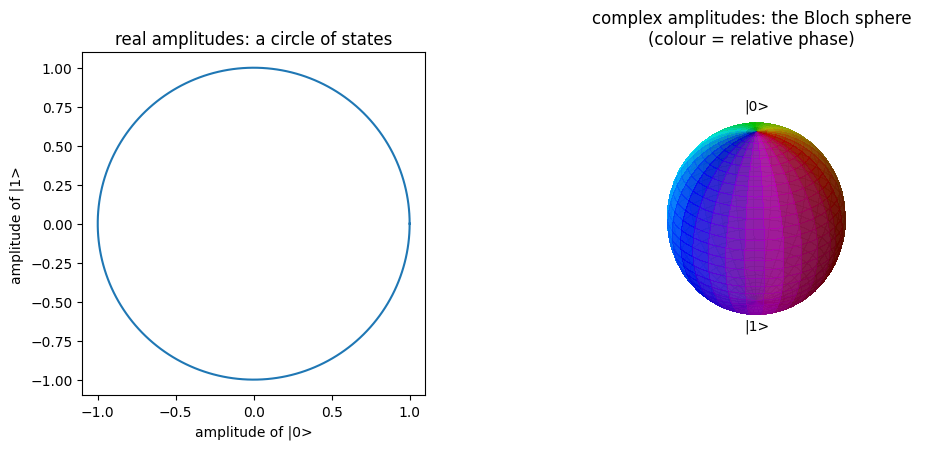

In [12]:
fig = plt.figure(figsize=(11, 4.6))

# real amplitudes only: the unit circle of states (cos t, sin t)
ax = fig.add_subplot(1, 2, 1)
t = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(t), np.sin(t), color="tab:blue")
ax.set_aspect("equal"); ax.set_xlabel("amplitude of |0>"); ax.set_ylabel("amplitude of |1>")
ax.set_title("real amplitudes: a circle of states")

# complex amplitudes: the Bloch sphere (state (cos th/2, e^{i ph} sin th/2) -> point on the sphere)
ax = fig.add_subplot(1, 2, 2, projection="3d")
th, ph = np.meshgrid(np.linspace(0, np.pi, 30), np.linspace(0, 2 * np.pi, 60))
X, Y, Z = np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)
ax.plot_surface(X, Y, Z, facecolors=plt.cm.hsv(ph / (2 * np.pi)), alpha=0.8, linewidth=0, antialiased=False)
ax.text(0, 0, 1.25, "|0>", ha="center"); ax.text(0, 0, -1.35, "|1>", ha="center")
ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()
ax.set_title("complex amplitudes: the Bloch sphere\n(colour = relative phase)")
plt.tight_layout(); plt.show()

### 3.4 Example for an ML engineer — a Hilbert space is a *feature space*

You have already used Hilbert spaces: the **kernel trick**. A feature map $\phi:\mathcal{X}\to\mathcal{H}$ sends data into a Hilbert space, and a kernel is the inner product there:

$$k(x, y) = \langle \phi(x), \phi(y)\rangle$$

Quantum machine learning does exactly this, with one twist: **$\phi(x)$ is a quantum state** — a unit vector in $\mathbb{C}^{2^n}$ prepared by a circuit. The "model" is then a kernel method (or a linear model) in that Hilbert space.

Below: the classical polynomial kernel evaluated two ways (explicit features vs. kernel), then a tiny **quantum-style feature map** $x\mapsto(\cos x, \sin x)$ whose kernel is $\cos^2(x-y)$.

In [13]:
# 1) Classical: polynomial kernel k(x,y) = (x·y)^2  <=>  explicit feature map in a bigger space
def phi_poly(x):                       # for x in R^2 : (x1², √2 x1x2, x2²)
    return np.array([x[0]**2, np.sqrt(2) * x[0] * x[1], x[1]**2])

x, y = np.array([1.0, 2.0]), np.array([3.0, -0.5])
print("kernel            :", (x @ y) ** 2)
print("<phi(x), phi(y)>  :", phi_poly(x) @ phi_poly(y))

kernel            : 4.0
<phi(x), phi(y)>  : 3.9999999999999987


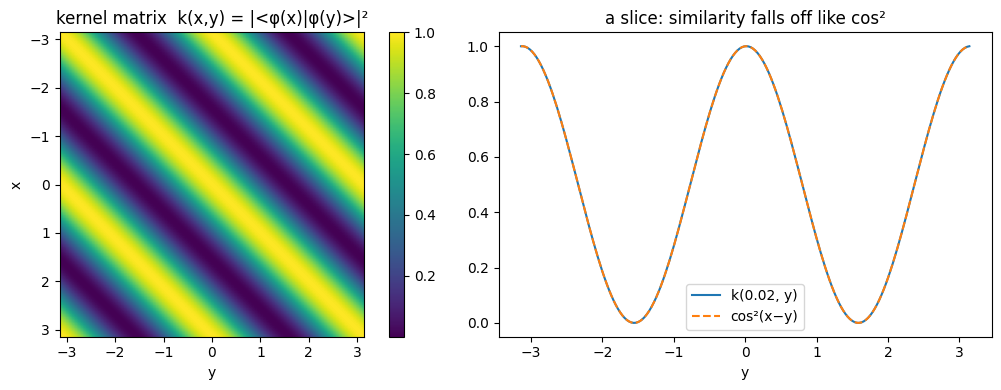

In [14]:
# 2) Quantum-style feature map: x -> unit vector (cos x, sin x)  (this is 'angle encoding', Week 3)
def phi_quantum(x):
    return np.array([np.cos(x), np.sin(x)], dtype=complex)

def quantum_kernel(x, y):
    return np.abs(np.vdot(phi_quantum(x), phi_quantum(y))) ** 2    # |<phi(x)|phi(y)>|^2

xs = np.linspace(-np.pi, np.pi, 200)
K = np.array([[quantum_kernel(a, b) for b in xs] for a in xs])

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
im = axs[0].imshow(K, extent=[-np.pi, np.pi, np.pi, -np.pi], cmap="viridis")
axs[0].set_title("kernel matrix  k(x,y) = |<φ(x)|φ(y)>|²"); axs[0].set_xlabel("y"); axs[0].set_ylabel("x")
plt.colorbar(im, ax=axs[0])
i0 = 100                                              # slice at x = xs[i0]
axs[1].plot(xs, K[i0], label=f"k({xs[i0]:.2f}, y)")
axs[1].plot(xs, np.cos(xs - xs[i0]) ** 2, "--", label="cos²(x−y)")
axs[1].set_title("a slice: similarity falls off like cos²"); axs[1].set_xlabel("y"); axs[1].legend()
plt.tight_layout(); plt.show()

---
## 4. Inner product

For $u, v\in\mathbb{C}^n$:

$$\langle u | v\rangle = \sum_i \overline{u_i}\, v_i, \qquad \|v\| = \sqrt{\langle v|v\rangle}$$

Two differences from the real dot product:
- the **first argument is conjugated** (so $\langle v|v\rangle$ is real and $\ge 0$);
- $\langle u|v\rangle$ is **complex in general** — its modulus is the "overlap", its angle is a relative phase.

`np.vdot(u, v)` conjugates the first argument — use it, not `u @ v`.

Key facts:

| Fact | Statement |
|---|---|
| Orthogonal | $\langle u\vert v\rangle = 0$ |
| Cauchy–Schwarz | $\lvert\langle u\vert v\rangle\rvert \le \lVert u\rVert\,\lVert v\rVert$ |
| Unit vector (valid quantum state) | $\lVert v\rVert = 1$ |
| **Born rule preview** | probability of outcome $i$ = $\lvert\langle i\vert\psi\rangle\rvert^2$ |

In [ ]:
u = np.array([1, 1j]) / np.sqrt(2)
v = np.array([1, -1j]) / np.sqrt(2)

print("<u|v>        =", np.vdot(u, v), "   -> orthogonal!")
print("<u|u>        =", np.vdot(u, u))
print("u @ u (WRONG)=", u @ u, "   <- no conjugate, not a norm")
print("np.linalg.norm(u) =", np.linalg.norm(u))

### Angle between states

The inner product also gives an **angle** between two states:

$$\cos\theta=\frac{\lvert\langle u|v\rangle\rvert}{\lVert u\rVert\,\lVert v\rVert},\qquad \theta\in[0^\circ,90^\circ]$$

so the overlap probability is $\lvert\langle u|v\rangle\rvert^2=\cos^2\theta$ for unit vectors. Orthogonal states have $\theta=90^\circ$. The modulus makes the angle blind to a global phase.

> **Hilbert-space angle vs. Bloch-sphere angle.** On the Bloch sphere the same pair of states is **twice** as far apart. $|0\rangle$ and $|1\rangle$ are orthogonal ($90^\circ$ in Hilbert space) yet sit at opposite poles ($180^\circ$ on the sphere).

In [ ]:
k0, k1 = np.array([1, 0], dtype=complex), np.array([0, 1], dtype=complex)
kplus, kminus, kplus_i = (k0 + k1) / np.sqrt(2), (k0 - k1) / np.sqrt(2), (k0 + 1j * k1) / np.sqrt(2)

def state_angle(u, v):
    c = abs(np.vdot(u, v)) / (np.linalg.norm(u) * np.linalg.norm(v))
    return np.degrees(np.arccos(np.clip(c, 0, 1)))

def bloch(psi):
    a, b = psi / np.linalg.norm(psi)
    return np.array([2 * (np.conj(a) * b).real, 2 * (np.conj(a) * b).imag, abs(a) ** 2 - abs(b) ** 2])

pairs = {"|0>, |1>": (k0, k1), "|0>, |+>": (k0, kplus), "|+>, |->": (kplus, kminus), "|0>, |+i>": (k0, kplus_i), "|+>, |+> (global phase i)": (kplus, 1j * kplus)}
print(f"{'pair':28s} {'Hilbert angle':>14s} {'Bloch angle':>12s}")
for name, (u_, v_) in pairs.items():
    ba = np.degrees(np.arccos(np.clip(bloch(u_) @ bloch(v_), -1, 1)))
    print(f"{name:28s} {state_angle(u_, v_):14.1f} {ba:12.1f}")

### Visualization — overlap as a function of angle

Take the real unit vectors $a=(1,0)$ and $b=(\cos t,\sin t)$. The **cosine similarity** is $\cos t$; the quantum overlap probability is its **square**, $|\langle a|b\rangle|^2=\cos^2 t$. Orthogonal vectors ($t=\pi/2$) have zero overlap; parallel ones have overlap 1.

In [ ]:
t = np.linspace(0, np.pi, 300)
a = np.array([1.0, 0.0])
overlap = np.array([np.vdot(a, [np.cos(ti), np.sin(ti)]) for ti in t])

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(t, overlap.real, label="cosine similarity  <a|b>")
axs[0].plot(t, np.abs(overlap) ** 2, label="probability  |<a|b>|²")
axs[0].axhline(0, color="gray", lw=0.6)
axs[0].set_xlabel("angle t between a and b"); axs[0].legend(); axs[0].set_title("similarity vs. probability")

for ti, c in zip([0, np.pi / 4, np.pi / 2], ["tab:blue", "tab:orange", "tab:green"]):
    axs[1].annotate("", xy=(np.cos(ti), np.sin(ti)), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2))
axs[1].plot(np.cos(t), np.sin(t), color="lightgray"); axs[1].set_aspect("equal")
axs[1].set_title("a=(1,0), b at 0°, 45°, 90°"); axs[1].set_xlim(-0.2, 1.3); axs[1].set_ylim(-0.2, 1.2)
plt.tight_layout(); plt.show()

### Example for an ML engineer — cosine similarity *is* the overlap

For real embeddings, **cosine similarity** is $\langle\hat a|\hat b\rangle$ with $\hat a=a/\lVert a\rVert$. Quantum states are complex, so the overlap is the Hermitian inner product, and the physically meaningful number is its **modulus** — which is invariant to a global phase, unlike the naive no-conjugate product `a @ b`. The same applies to complex embeddings such as FFT features or ComplEx knowledge-graph embeddings.

In [ ]:
# real embeddings: cosine similarity == inner product of the normalized vectors
a_r, b_r = rng.normal(size=8), rng.normal(size=8)
print("cosine similarity       :", a_r @ b_r / (np.linalg.norm(a_r) * np.linalg.norm(b_r)))
print("<a_hat|b_hat>           :", np.vdot(a_r / np.linalg.norm(a_r), b_r / np.linalg.norm(b_r)))

# complex embeddings: |<a|b>| ignores global phase, a @ b does not
a_c = rng.normal(size=8) + 1j * rng.normal(size=8)
b_c = rng.normal(size=8) + 1j * rng.normal(size=8)
b_c2 = np.exp(1j * 1.1) * b_c                              # same state, different global phase
print("\n|<a|b>|  :", abs(np.vdot(a_c, b_c)), "  |<a|b e^{i g}>| :", abs(np.vdot(a_c, b_c2)))
print("a @ b     :", a_c @ b_c, "  a @ (b e^{i g}) :", a_c @ b_c2, "  <- changes!")

---
## 5. Norm and normalization

### 5.1 Norm = length

$$\lVert v\rVert=\sqrt{\langle v|v\rangle}=\sqrt{\sum_i\lvert v_i\rvert^2}$$

It is the length of the vector, built from the **moduli** of the amplitudes (so complex entries still give a real length).

| Property | Statement |
|---|---|
| Positive | $\lVert v\rVert\ge0$, and $=0$ only for $v=0$ |
| Homogeneous | $\lVert c\,v\rVert=\lvert c\rvert\,\lVert v\rVert$ |
| Triangle inequality | $\lVert u+v\rVert\le\lVert u\rVert+\lVert v\rVert$ |
| **Phase-blind** | $\lVert e^{i\gamma}v\rVert=\lVert v\rVert$ |

### 5.2 Normalization

Dividing by the length gives a **unit vector**: $\hat v=v/\lVert v\rVert$.

**Why quantum states must be normalized.** The Born rule says outcome $i$ has probability $\lvert v_i\rvert^2$. Probabilities must sum to 1, i.e. $\sum_i\lvert v_i\rvert^2=\lVert v\rVert^2=1$. So a **normalized quantum state is exactly a unit vector** in the Hilbert space.

- Normalizing removes only the overall scale. The **ratios** of amplitudes and the **relative phases** are untouched — vectors that differ by a nonzero complex factor describe the same state.
- Example: $(1,\,2i)$ has $\lVert\cdot\rVert^2=1+4=5$, so the state is $(1,\,2i)/\sqrt5$ with probabilities $(0.2,\,0.8)$.

In [ ]:
def norm(v): return np.sqrt(np.vdot(v, v).real)
def normalize(v):
    n = norm(v); assert n > 0, "cannot normalize the zero vector"
    return v / n

v = np.array([1, 2j]); w = np.array([0.5 - 1j, 2.0 + 0.3j])
print("||v||                     :", norm(v), "  (sqrt 5 =", np.sqrt(5), ")")
print("||c v|| = |c| ||v||        :", norm((2 + 1j) * v), "=", abs(2 + 1j) * norm(v))
print("triangle ||v+w|| <= sum    :", norm(v + w), "<=", norm(v) + norm(w))
print("global phase keeps norm    :", norm(np.exp(1j * 0.7) * v))

vhat = normalize(v)
print("\nnormalized                 :", vhat, "  norm =", norm(vhat))
print("probabilities |v_i|^2      :", np.abs(vhat) ** 2, "  sum =", np.sum(np.abs(vhat) ** 2))
print("relative phase preserved   :", np.angle(vhat[1]) - np.angle(vhat[0]), "=", np.angle(v[1]) - np.angle(v[0]))

### Visualization — normalizing

Left: vectors of different lengths all land on the **unit circle** after normalization, keeping their direction. Right: the squared moduli of $(1,2i)$ before normalization sum to 5 — not probabilities — and after normalization sum to 1.

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))

ax = axs[0]
t = np.linspace(0, 2 * np.pi, 200); ax.plot(np.cos(t), np.sin(t), color="lightgray")
for vec, c in zip([np.array([2.0, 1.0]), np.array([-1.5, 2.5]), np.array([0.4, -0.3])], ["tab:blue", "tab:orange", "tab:green"]):
    ax.annotate("", xy=vec, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=1.6, alpha=0.35))
    nv = vec / np.linalg.norm(vec)
    ax.annotate("", xy=nv, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2.8))
ax.axhline(0, color="gray", lw=0.6); ax.axvline(0, color="gray", lw=0.6)
ax.set_aspect("equal"); ax.set_xlim(-2, 2.6); ax.set_ylim(-1.5, 3); ax.grid(alpha=0.3)
ax.set_title("faint = original, bold = normalized (on the unit circle)")

ax = axs[1]
before, after = np.abs(v) ** 2, np.abs(vhat) ** 2
x = np.arange(2); w_ = 0.36
ax.bar(x - w_ / 2, before, w_, label=f"before: sum = {before.sum():.0f}", color="tab:red")
ax.bar(x + w_ / 2, after, w_, label=f"after: sum = {after.sum():.0f}", color="tab:blue")
ax.set_xticks(x); ax.set_xticklabels(["|v₀|²", "|v₁|²"]); ax.legend(); ax.set_title("squared amplitudes of (1, 2i)")
plt.tight_layout(); plt.show()

### Example for an ML engineer — L2-normalized embeddings *are* quantum states

Take any embedding $e\in\mathbb{R}^d$. After $e\mapsto e/\|e\|$ it is a valid (real) state, and:

- **cosine similarity** of two embeddings = their inner product $\langle a|b\rangle$;
- squaring the entries of a unit vector gives a **probability distribution** — like softmax, but with a different nonlinearity ($p_i = z_i^2$ instead of $e^{z_i}/\sum e^{z_j}$).

That second point *is* the Born rule: a quantum model outputs $p_i=|\psi_i|^2$.

In [ ]:
logits = rng.normal(size=5)
softmax = np.exp(logits) / np.exp(logits).sum()

state = logits / np.linalg.norm(logits)          # L2-normalize -> valid "quantum state"
born = state ** 2                                 # Born rule

print("softmax :", softmax, "  sum =", softmax.sum())
print("born    :", born,    "  sum =", born.sum())

fig, ax = plt.subplots(figsize=(6, 3.2))
w = 0.38; i = np.arange(5)
ax.bar(i - w/2, softmax, w, label="softmax(logits)"); ax.bar(i + w/2, born, w, label="Born: (z/‖z‖)²")
ax.set_xlabel("class"); ax.set_ylabel("probability"); ax.legend(); plt.tight_layout(); plt.show()

---
## 6. Basis and change of basis

**Dirac (bra–ket) notation** is just compact linear algebra:

| Notation | Meaning | numpy |
|---|---|---|
| $\lvert v\rangle$ ("ket") | column vector | `v` |
| $\langle v\rvert$ ("bra") | conjugate transpose (row) | `v.conj()` |
| $\langle u\vert v\rangle$ | inner product (a number) | `np.vdot(u, v)` |
| $\lvert u\rangle\langle v\rvert$ | outer product (a matrix) | `np.outer(u, v.conj())` |

An **orthonormal basis** $\{|e_i\rangle\}$ satisfies $\langle e_i|e_j\rangle=\delta_{ij}$. Any state expands as

$$|\psi\rangle = \sum_i c_i |e_i\rangle, \qquad c_i = \langle e_i|\psi\rangle, \qquad \sum_i |c_i|^2 = 1$$

and the projectors $|e_i\rangle\langle e_i|$ sum to the identity (**completeness**). Two bases for a qubit you will use constantly:

- computational (Z) basis: $|0\rangle, |1\rangle$
- Hadamard (X) basis: $|\pm\rangle = (|0\rangle\pm|1\rangle)/\sqrt2$

In [ ]:
ket0 = np.array([1, 0], dtype=complex)
ket1 = np.array([0, 1], dtype=complex)
plus  = (ket0 + ket1) / np.sqrt(2)
minus = (ket0 - ket1) / np.sqrt(2)

Z_basis = [ket0, ket1]
X_basis = [plus, minus]

# completeness: sum of projectors = identity
print(sum(np.outer(e, e.conj()) for e in Z_basis).real)
print(sum(np.outer(e, e.conj()) for e in X_basis).real)

def coefficients(psi, basis):
    return np.array([np.vdot(e, psi) for e in basis])

### Change of basis as a matrix

Stack an orthonormal basis as the **columns** of a matrix $B=[\,e_1\;e_2\;\cdots\,]$. Then

$$c = B^\dagger\psi\quad(\text{coordinates in the new basis}),\qquad \psi=B\,c\quad(\text{back to the old}).$$

$B$ is **unitary**, so the change of basis preserves lengths. For the Hadamard (X) basis, $B=[\,|+\rangle\;|-\rangle\,]=\tfrac1{\sqrt2}\begin{bmatrix}1&1\\1&-1\end{bmatrix}$ — the **Hadamard matrix**. That is why the Hadamard *gate* turns "Z-basis questions" into "X-basis questions".

*(If the basis is not orthonormal you need $B^{-1}$ instead of $B^\dagger$.)*

In [ ]:
Hh = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
B = np.column_stack(X_basis)                         # columns: |+>, |->
psi = np.array([3 / 5, 4j / 5])

c = B.conj().T @ psi                                 # coordinates in the X basis
print("B == Hadamard matrix :", np.allclose(B, Hh))
print("B unitary            :", np.allclose(B.conj().T @ B, np.eye(2)))
print("coordinates c        :", c, "   sum |c|^2 =", np.sum(np.abs(c) ** 2))
print("matches coefficients():", np.allclose(c, coefficients(psi, X_basis)))
print("round trip  B c == psi:", np.allclose(B @ c, psi))

### Visualization — same state, two bases

The state is a fixed arrow; the **coefficients** depend on which axes you measure against. Rotating the axes by 45° turns "50/50" into "100/0".

In [ ]:
psi = plus                                         # try: ket0, minus, or a random normalized vector

pz = np.abs(coefficients(psi, Z_basis)) ** 2
px = np.abs(coefficients(psi, X_basis)) ** 2

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))

# real-plane picture: arrow psi, with Z axes and X axes
t = np.linspace(0, 2 * np.pi, 200)
axs[0].plot(np.cos(t), np.sin(t), color="lightgray", lw=0.8)
for e, c, lab in [(ket0, "tab:blue", "|0>"), (ket1, "tab:blue", "|1>"), (plus, "tab:orange", "|+>"), (minus, "tab:orange", "|->")]:
    axs[0].plot([0, e[0].real], [0, e[1].real], color=c, lw=1, ls="--")
    axs[0].text(e[0].real * 1.15, e[1].real * 1.15, lab, color=c, ha="center")
axs[0].annotate("", xy=(psi[0].real, psi[1].real), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="crimson", lw=2.5))
axs[0].set_aspect("equal"); axs[0].set_xlim(-1.4, 1.4); axs[0].set_ylim(-1.4, 1.4); axs[0].set_title("ψ and the two bases (real slice)")

axs[1].bar(["|0>", "|1>"], pz, color="tab:blue"); axs[1].set_ylim(0, 1); axs[1].set_title("probabilities in Z basis")
axs[2].bar(["|+>", "|->"], px, color="tab:orange"); axs[2].set_ylim(0, 1); axs[2].set_title("probabilities in X basis")
plt.tight_layout(); plt.show()

### Example for an ML engineer — coefficients are PCA-style coordinates

Computing $c_i=\langle e_i|\psi\rangle$ is exactly projecting a vector onto an orthonormal basis, as in **PCA**: the principal components form an orthonormal basis, and the "scores" are inner products with them. Changing the measurement basis in QML is the same as choosing different principal axes — the vector is unchanged, only its coordinates are.

Below, an orthonormal basis from PCA of random 2-D data; the squared normalized scores play the role of measurement probabilities.

In [ ]:
X = rng.normal(size=(500, 2)) @ np.array([[2.0, 0.5], [0.0, 0.6]])
X -= X.mean(0)
_, _, Vt = np.linalg.svd(X, full_matrices=False)        # rows of Vt: orthonormal basis (principal axes)

x0 = X[0] / np.linalg.norm(X[0])                         # one sample, as a unit vector
scores_pca = Vt @ x0                                     # coefficients  c_i = <e_i|x>
scores_std = np.eye(2) @ x0                              # coefficients in the standard basis

print("Σ c_i² (PCA basis)      :", np.sum(scores_pca ** 2))
print("Σ c_i² (standard basis) :", np.sum(scores_std ** 2))
print("same vector, different coordinates:", scores_std, "vs", scores_pca)

---
## 7. Linear transformations: matrices acting on vectors

### 7.1 What a linear map is

A map $A:\mathbb{C}^n\to\mathbb{C}^m$ is **linear** if

$$A(\alpha u+\beta v)=\alpha\,Au+\beta\,Av.$$

Every linear map is a **matrix**, and the matrix is read off from what it does to the basis vectors: **column $j$ of $A$ is $A e_j$**. Applying it is the matrix–vector product $(A\psi)_i=\sum_jA_{ij}\psi_j$.

- **Superposition principle.** Quantum evolution is linear: a gate acts on every branch of a superposition separately.
- **Composition is multiplication, and order matters.** "First $A$, then $B$" is $BA$, and $AB\neq BA$ in general (for instance $XZ=-ZX$).
- **Matrix elements:** $A_{ij}=\langle e_i|A|e_j\rangle$, and $A=\sum_{ij}A_{ij}\,|e_i\rangle\langle e_j|$ (outer products).
- The **adjoint** $A^\dagger=\overline{A}^{\,T}$ satisfies $\langle u|Av\rangle=\langle A^\dagger u|v\rangle$.

In [ ]:
Xg = np.array([[0, 1], [1, 0]], dtype=complex)
Zg = np.array([[1, 0], [0, -1]], dtype=complex)
Hg = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)

a, b = 0.3 + 0.4j, -0.2 + 0.9j
u2 = np.array([0.6, 0.8j]); v2 = np.array([1, 1j]) / np.sqrt(2)
print("linearity     :", np.allclose(Hg @ (a * u2 + b * v2), a * (Hg @ u2) + b * (Hg @ v2)))

print("column 0 of H :", Hg[:, 0], "= H|0> =", Hg @ ket0)
print("<0|H|1>       :", np.vdot(ket0, Hg @ ket1), "= H[0,1] =", Hg[0, 1])
print("X from outer products |0><1| + |1><0| :\n", np.outer(ket0, ket1.conj()) + np.outer(ket1, ket0.conj()))

print("\nXZ == ZX  :", np.allclose(Xg @ Zg, Zg @ Xg))
print("XZ == -ZX :", np.allclose(Xg @ Zg, -Zg @ Xg))
print("adjoint rule <u|Av> = <A†u|v> :", np.isclose(np.vdot(u2, Hg @ v2 * 1j), np.vdot((1j * Hg).conj().T @ u2, v2)))

### Visualization — a matrix moves the whole grid

A real $2\times2$ matrix drags the coordinate grid. The two coloured arrows are the **columns** $Ae_1$ and $Ae_2$: they say where the basis vectors land, and so determine where *everything* lands. Straight lines stay straight and the origin stays fixed — that is what "linear" looks like.

In [ ]:
def draw_grid(ax, M, title):
    ks = np.linspace(-3, 3, 13)
    for k in ks:
        for line in (np.array([[k, k], [-3, 3]]), np.array([[-3, 3], [k, k]])):
            p = M @ line
            ax.plot(p[0], p[1], color="lightsteelblue", lw=0.8)
    for col, c, lab in ((M[:, 0], "tab:blue", "A e₁"), (M[:, 1], "tab:green", "A e₂")):
        ax.annotate("", xy=col, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2.8))
        ax.text(col[0] * 1.12, col[1] * 1.12, lab, color=c)
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal"); ax.set_title(title)

ang = np.deg2rad(30)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.4))
draw_grid(axs[0], np.eye(2), "identity")
draw_grid(axs[1], np.array([[1.0, 0.8], [0.3, 1.2]]), "general linear map")
draw_grid(axs[2], np.array([[np.cos(ang), -np.sin(ang)], [np.sin(ang), np.cos(ang)]]), "rotation")
plt.tight_layout(); plt.show()

### Example for an ML engineer — a stack of linear layers is one matrix

A dense layer without activation is a linear map $y=Wx$; the columns of $W$ are the images of the input features. Two such layers collapse into **one** matrix $W_2W_1$ — the reason you need nonlinearities. A quantum circuit is the same: ten gates multiply into **one** unitary. The only nonlinearity in a quantum model enters through **measurement** (squaring the amplitudes) and through how the data is encoded.

In [ ]:
W1, W2 = rng.normal(size=(4, 3)), rng.normal(size=(2, 4))
x = rng.normal(size=3)
print("two linear layers == one matrix W2@W1 :", np.allclose(W2 @ (W1 @ x), (W2 @ W1) @ x))

U = Hg @ Zg @ Hg @ Xg @ Hg                         # five gates -> one 2x2 matrix
step = Hg @ (Xg @ (Hg @ (Zg @ (Hg @ ket0))))
print("circuit collapses to a single matrix  :", np.allclose(U @ ket0, step), "\n", U)

psi = U @ ket0
print("\ndoubling the input state: amplitudes x2, probabilities x4 ->", np.abs(2 * psi) ** 2 / np.abs(psi) ** 2)

---
## 8. Eigenvalues and eigenvectors

### 8.1 The eigenvalue equation

$$A\,|v\rangle=\lambda\,|v\rangle,\qquad |v\rangle\neq0$$

Most vectors change direction when a matrix acts on them. **Eigenvectors are the special directions that $A$ only stretches** — by the **eigenvalue** $\lambda\in\mathbb{C}$ (a negative or complex $\lambda$ flips or phase-rotates the vector). They are found from $\det(A-\lambda I)=0$.

### 8.2 What eigenvalues mean in quantum computing

**Hermitian matrices ($H^\dagger=H$) — observables.**
- eigenvalues are **real**, eigenvectors for different eigenvalues are **orthogonal**, and they form an orthonormal basis;
- **spectral decomposition:** $O=\sum_k\lambda_k\,|v_k\rangle\langle v_k|$;
- **measuring $O$** returns an eigenvalue $\lambda_k$ with probability $\lvert\langle v_k|\psi\rangle\rvert^2$ and leaves the state in $|v_k\rangle$; the average is $\langle O\rangle=\sum_k\lambda_kp_k=\langle\psi|O|\psi\rangle$.

**Unitary matrices — gates.** Eigenvalues have modulus 1, $\lambda=e^{i\varphi}$: the gate only applies a **phase** to its eigenvectors.

| Matrix | Eigenvalues | Eigenvectors |
|---|---|---|
| $Z$ | $+1,\,-1$ | $\lvert0\rangle,\,\lvert1\rangle$ (computational basis) |
| $X$ | $+1,\,-1$ | $\lvert+\rangle,\,\lvert-\rangle$ (Hadamard basis) |
| $Y$ | $+1,\,-1$ | $\lvert{+i}\rangle,\,\lvert{-i}\rangle$ |
| $S=\mathrm{diag}(1,i)$ | $1,\,i$ | $\lvert0\rangle,\,\lvert1\rangle$ |
| $R_Z(\theta)$ | $e^{-i\theta/2},\,e^{+i\theta/2}$ | $\lvert0\rangle,\,\lvert1\rangle$ |

So "measure in the computational basis" means "measure $Z$", and "measure in the Hadamard basis" means "measure $X$" — the bases of section 6 are the eigenbases of these observables.

In [ ]:
Yg = np.array([[0, -1j], [1j, 0]])
Sg = np.diag([1, 1j])
def rz(t): return np.diag([np.exp(-0.5j * t), np.exp(0.5j * t)])

# Hermitian observables: real eigenvalues, A v = lambda v
for name, M in {"Z": Zg, "X": Xg, "Y": Yg}.items():
    vals, vecs = np.linalg.eigh(M)
    ok = all(np.allclose(M @ vecs[:, k], vals[k] * vecs[:, k]) for k in range(2))
    print(f"{name}: eigenvalues {vals}   A v = lambda v for all: {ok}   eigenvectors orthonormal: {np.allclose(vecs.conj().T @ vecs, np.eye(2))}")

# spectral decomposition + measurement statistics of X on a state
vals, vecs = np.linalg.eigh(Xg)
rebuilt = sum(l * np.outer(vecs[:, k], vecs[:, k].conj()) for k, l in enumerate(vals))
print("\nX = sum lambda |v><v| :", np.allclose(rebuilt, Xg))

psi = np.array([3 / 5, 4 / 5], dtype=complex)
p = np.abs(vecs.conj().T @ psi) ** 2
print("measuring X on psi -> outcomes", vals, "with probabilities", p)
print("<X> = sum lambda p    :", np.sum(vals * p), "   <psi|X|psi> =", np.vdot(psi, Xg @ psi).real)

# unitary: eigenvalues on the unit circle
Q, _ = np.linalg.qr(rng.normal(size=(3, 3)) + 1j * rng.normal(size=(3, 3)))
print()
for name, U_ in {"H": Hg, "S": Sg, "RZ(0.7)": rz(0.7), "random 3x3 unitary": Q}.items():
    ev = np.linalg.eigvals(U_)
    print(f"{name:20s} eigenvalues {np.round(ev, 3)}   |lambda| = {np.round(np.abs(ev), 6)}")

### Visualization — eigenvectors keep their direction

Left: a symmetric matrix $A=\begin{bmatrix}2&1\\1&2\end{bmatrix}$ turns the unit circle into an ellipse. Along its two eigenvectors the matrix acts as **pure stretching**: the green unit eigenvector maps to the red arrow on the same line, scaled by $\lambda$ (3 and 1). Right: where eigenvalues live in the complex plane — **Hermitian** matrices on the real axis, **unitary** matrices on the unit circle.

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5.2))

# --- left: ellipse and eigen-axes
A = np.array([[2.0, 1.0], [1.0, 2.0]])
lam, V = np.linalg.eigh(A)
t = np.linspace(0, 2 * np.pi, 300)
P = np.vstack([np.cos(t), np.sin(t)]); E = A @ P
ax = axs[0]
ax.plot(P[0], P[1], color="lightgray", label="unit circle"); ax.plot(E[0], E[1], color="tab:blue", label="A · circle")
for k, c in zip(range(2), ["tab:orange", "tab:red"]):
    v = V[:, k]
    ax.plot([-3 * v[0], 3 * v[0]], [-3 * v[1], 3 * v[1]], ":", color="gray")
    ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="tab:green", lw=2.5))
    ax.annotate("", xy=lam[k] * v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="crimson", lw=2.5))
    ax.text(*(lam[k] * v * 1.1), f"λ = {lam[k]:.0f}", color="crimson")
ax.set_aspect("equal"); ax.set_xlim(-3.6, 3.6); ax.set_ylim(-3.6, 3.6); ax.grid(alpha=0.3); ax.legend(loc="lower right")
ax.set_title("eigenvectors: same direction before (green) and after (red)")

# --- right: eigenvalues in the complex plane
ax = axs[1]
ax.plot(np.cos(t), np.sin(t), color="lightgray"); ax.axhline(0, color="gray", lw=0.6); ax.axvline(0, color="gray", lw=0.6)
Ah = rng.normal(size=(5, 5)) + 1j * rng.normal(size=(5, 5)); Ah = (Ah + Ah.conj().T) / 2
Q6, _ = np.linalg.qr(rng.normal(size=(6, 6)) + 1j * rng.normal(size=(6, 6)))
herm = np.concatenate([np.linalg.eigvalsh(M) for M in (Zg, Xg, Yg)] + [np.linalg.eigvalsh(Ah) / 3]).astype(complex)
unit = np.concatenate([np.linalg.eigvals(M) for M in (Hg, Sg, rz(0.7), Q6)])
ax.scatter(herm.real, herm.imag, s=70, marker="o", label="Hermitian (real axis)")
ax.scatter(unit.real, unit.imag, s=70, marker="^", label="unitary (|λ| = 1)")
ax.set_aspect("equal"); ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.3, 1.3); ax.legend(loc="upper left")
ax.set_xlabel("Re λ"); ax.set_ylabel("Im λ"); ax.set_title("where eigenvalues live")
plt.tight_layout(); plt.show()

### 8.3 Example for an ML engineer — PCA is an eigendecomposition

The covariance matrix $C$ is Hermitian (real symmetric). Its eigenvectors are the **principal axes** and its eigenvalues are the **variances** along them — the same spectral decomposition $C=\sum_k\lambda_k|v_k\rangle\langle v_k|$ as an observable, with "outcome probability" replaced by "share of variance". When the matrix is too big to diagonalize, **power iteration** (repeated multiplication and normalization, as in PageRank) converges to the top eigenvector.

In [ ]:
Xd = rng.normal(size=(600, 2)) @ np.array([[2.0, 0.9], [0.0, 0.6]])
Xd -= Xd.mean(0)
C = Xd.T @ Xd / len(Xd)
lam_c, V_c = np.linalg.eigh(C)                       # ascending order

for k in (1, 0):
    print(f"eigenvalue {lam_c[k]:.3f}   variance of data along its eigenvector = {np.var(Xd @ V_c[:, k]):.3f}")

v = rng.normal(size=2)
for _ in range(50):
    v = C @ v; v /= np.linalg.norm(v)                # power iteration
print("power iteration vs top eigenvector |cos| =", abs(v @ V_c[:, 1]))

plt.figure(figsize=(5.5, 5))
plt.scatter(Xd[:, 0], Xd[:, 1], s=6, alpha=0.4)
for k, c in [(1, "crimson"), (0, "tab:green")]:
    plt.annotate("", xy=2 * np.sqrt(lam_c[k]) * V_c[:, k], xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2.8))
plt.gca().set_aspect("equal"); plt.grid(alpha=0.3)
plt.title("eigenvectors of the covariance = principal axes (length 2·√λ)"); plt.show()

---
## 9. Preview — unitaries and Hermitian operators

> A first look. `2_quantum_mathematics.ipynb` (topics 10–11) develops these in depth.

A **linear operator** is a matrix $A$ acting on $|\psi\rangle$. Its **adjoint** is $A^\dagger=\overline{A}^{T}$ (conjugate transpose).

| Type | Condition | Role in QML |
|---|---|---|
| **Unitary** | $U^\dagger U = I$ | quantum **gates** — the layers of a circuit |
| **Hermitian** | $H^\dagger = H$ | **observables** — real eigenvalues, the measurable quantities |

**Unitaries preserve inner products and norms**: $\langle U u|U v\rangle=\langle u|v\rangle$. So a gate can never turn a valid state into an invalid one — it only *rotates* in $\mathbb{C}^n$. (Real unitaries are the orthogonal matrices you know.)

**Observables and expectation values.** For Hermitian $O$ the expectation is

$$\langle O\rangle_\psi = \langle\psi|O|\psi\rangle \in \mathbb{R}$$

and this number is the **output of a quantum model**. Example, Pauli-Z $=\mathrm{diag}(1,-1)$: $\langle Z\rangle = P(0)-P(1)$.

In [ ]:
def is_unitary(U): return np.allclose(U.conj().T @ U, np.eye(len(U)))
def is_hermitian(H): return np.allclose(H, H.conj().T)

X_gate = np.array([[0, 1], [1, 0]], dtype=complex)
Z_gate = np.array([[1, 0], [0, -1]], dtype=complex)
H_gate = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)

for name, M in [("X", X_gate), ("Z", Z_gate), ("H", H_gate)]:
    print(f"{name}: unitary={is_unitary(M)}  hermitian={is_hermitian(M)}")

print("not unitary:", is_unitary(np.array([[1, 1], [0, 1]], dtype=complex)))

psi = np.array([3/5, 4/5], dtype=complex)
print("<Z> =", np.vdot(psi, Z_gate @ psi).real, "  vs  P(0)-P(1) =", 0.36 - 0.64)

### Visualization — unitary = rigid rotation, non-unitary = distortion

Push the unit circle through three matrices. A unitary (here a real rotation) keeps every point on the circle. A shear changes lengths and angles — such a map cannot be a quantum gate.

In [ ]:
theta = np.deg2rad(35)
R = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])   # unitary (orthogonal)
S = np.array([[1.0, 0.8], [0.0, 1.0]])                                             # shear: not unitary

t = np.linspace(0, 2 * np.pi, 120)
P = np.vstack([np.cos(t), np.sin(t)])

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, M) in zip(axs, [("identity", np.eye(2)), ("rotation (unitary)", R), ("shear (NOT unitary)", S)]):
    Q = M @ P
    ax.plot(np.cos(t), np.sin(t), color="lightgray")
    ax.scatter(Q[0], Q[1], c=t, cmap="hsv", s=10)
    ax.set_aspect("equal"); ax.set_xlim(-2, 2); ax.set_ylim(-2, 2)
    ax.set_title(f"{name}\nmax |norm-1| = {np.abs(np.linalg.norm(Q, axis=0) - 1).max():.2f}")
plt.tight_layout(); plt.show()

### Example for an ML engineer — orthogonal/unitary maps never explode or vanish

Deep nets and RNNs suffer from exploding/vanishing signals because repeated multiplication by $W$ scales the norm like $\|W\|^k$. **Orthogonal initialization** and **unitary RNNs** fix this by using norm-preserving maps — exactly the property quantum circuits have for free. Stacking 50 gates keeps the state valid.

In [ ]:
n, depth = 64, 50
x0 = rng.normal(size=n); x0 /= np.linalg.norm(x0)

def run(make_W):
    x, norms = x0.copy(), []
    for _ in range(depth):
        x = make_W() @ x
        norms.append(np.linalg.norm(x))
    return norms

gauss = lambda s: (lambda: s * rng.normal(size=(n, n)) / np.sqrt(n))
Qmat, _ = np.linalg.qr(rng.normal(size=(n, n)))                    # one fixed orthogonal matrix

plt.semilogy(run(gauss(1.1)), label="random W, slightly too big (×1.1)")
plt.semilogy(run(gauss(0.9)), label="random W, slightly too small (×0.9)")
plt.semilogy(run(lambda: Qmat), label="orthogonal / unitary W")
plt.xlabel("layer"); plt.ylabel("‖x‖"); plt.legend(); plt.title("norm after repeated multiplication"); plt.show()

---
## 10. Preview — tensor product

> A first look. `2_quantum_mathematics.ipynb` (topic 12) develops this in depth.

To combine two systems, take the **tensor (Kronecker) product** of their spaces: $\mathbb{C}^m\otimes\mathbb{C}^n=\mathbb{C}^{mn}$.

$$\begin{pmatrix}a\\b\end{pmatrix}\otimes\begin{pmatrix}c\\d\end{pmatrix}=\begin{pmatrix}ac\\ad\\bc\\bd\end{pmatrix}$$

- Dimensions **multiply** — hence $2^n$ for $n$ qubits.
- Gates on separate qubits combine as $A\otimes B$.
- Not every vector in $\mathbb{C}^4$ is a product $u\otimes v$. The rest are **entangled**.

Reshape the 4-vector into a $2\times2$ matrix $M_{ij}$: a product state is exactly a **rank-1** matrix ($M = u v^T$).

In [ ]:
u = np.array([1, 2j]) / np.sqrt(5)
v = np.array([3, 4]) / 5
prod = np.kron(u, v)                                   # product state in C^4
bell = np.array([1, 0, 0, 1], dtype=complex) / np.sqrt(2)

print("kron(u, v) =", prod)
print("rank of reshape(product) =", np.linalg.matrix_rank(prod.reshape(2, 2)))
print("rank of reshape(bell)    =", np.linalg.matrix_rank(bell.reshape(2, 2)))

### Visualization — product vs. entangled as a 2×2 matrix

The reshaped amplitude matrix of a product state has a clean outer-product structure (rank 1). The Bell state is diagonal with equal entries — rank 2, cannot be factored.

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, (name, s) in zip(axs, [("product  u⊗v  (rank 1)", prod), ("Bell state  (rank 2)", bell)]):
    M = np.abs(s.reshape(2, 2))
    ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
    for (i, j), val in np.ndenumerate(M):
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color="white" if val > 0.5 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xlabel("qubit B"); ax.set_ylabel("qubit A")
    ax.set_title(f"{name}\n singular values: {np.round(np.linalg.svd(s.reshape(2,2), compute_uv=False), 2)}", fontsize=9)
plt.tight_layout(); plt.show()

### Example for an ML engineer — feature crossing and low-rank structure

- `np.kron(u, v)` is the **outer-product / feature-crossing** layer: all pairwise products $u_iv_j$ (as in bilinear pooling, factorization machines).
- A product state is a **rank-1 tensor**; an entangled state is a higher-rank one. Quantum "expressivity" partly means access to correlations that low-rank (product) models miss — the same trade-off as rank in matrix/tensor factorization.

In [ ]:
# A 'user' embedding x 'item' embedding, crossed: rank-1 by construction
user = rng.normal(size=3); item = rng.normal(size=4)
crossed = np.kron(user, item).reshape(3, 4)
print("crossed shape:", crossed.shape, "  rank:", np.linalg.matrix_rank(crossed))

# A generic interaction matrix is NOT rank-1 -> needs a sum of crosses (= 'entangled')
generic = rng.normal(size=(3, 4))
print("generic rank :", np.linalg.matrix_rank(generic))

---
## 11. Exercises

Do them on paper first, then verify in code.

**Exercise 1 — complex arithmetic.** Compute $(1+2i)(3-i)$ and $|1+2i|$ by hand, then check with Python complex numbers. What does multiplying by $i$ do geometrically?

In [ ]:
# TODO

**Exercise 2 — inner product.** For $u=(1, i)/\sqrt2$ and $v=(1, 1)/\sqrt2$ compute $\langle u|v\rangle$, $\langle v|u\rangle$, and $|\langle u|v\rangle|^2$. How are the first two related?

In [ ]:
# TODO

**Exercise 3 — orthonormal basis.** Show that $\{(1,i)/\sqrt2,\ (1,-i)/\sqrt2\}$ is an orthonormal basis of $\mathbb{C}^2$. Expand $|0\rangle$ in it and check $\sum|c_i|^2=1$.

In [ ]:
# TODO

**Exercise 4 — unitarity.** Write `is_unitary` for the matrix $\begin{pmatrix}1&0\\0&i\end{pmatrix}$ and for $\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ (without the $1/\sqrt2$). Which are unitary? Fix the second.

In [ ]:
# TODO

**Exercise 5 — expectation.** For $|\psi\rangle=(\cos\tfrac{\theta}{2},\sin\tfrac{\theta}{2})$ show $\langle Z\rangle=\cos\theta$ and plot it for $\theta\in[0,2\pi]$. Why is this the shape of a QML model's output as a function of a rotation angle?

In [ ]:
# TODO

**Exercise 6 — tensor product.** Build $|+\rangle\otimes|-\rangle$, list its 4 amplitudes, and verify it has rank 1. Then check that $\tfrac{1}{\sqrt2}(|01\rangle+|10\rangle)$ has rank 2.

In [ ]:
# TODO

**Exercise 7 (ML link).** Write a kernel $k(x,y)=|\langle\phi(x)|\phi(y)\rangle|^2$ with $\phi(x)=(\cos x,\sin x)$ and fit scikit-learn's `SVC(kernel='precomputed')` on `make_moons` after scaling features to $[0,\pi]$ (use only the first feature). Report accuracy vs. an RBF kernel.

In [ ]:
# TODO

**Exercise 8 — Euler.** Show numerically that $e^{i\pi}+1=0$. Then use $e^{i\alpha}e^{i\beta}=e^{i(\alpha+\beta)}$ and Euler's formula to derive $\cos(\alpha+\beta)=\cos\alpha\cos\beta-\sin\alpha\sin\beta$ (compare real parts), and verify it for two angles.

In [ ]:
# TODO

**Exercise 9 — normalization.** Normalize $(1+i,\ 2,\ -i)$ and report the three outcome probabilities. Multiply the state by $e^{0.7i}$ and show the probabilities do not change. Multiply only the *second* component by $e^{0.7i}$ — do the probabilities change? Does the state?

In [ ]:
# TODO

**Exercise 10 — angles.** Compute the Hilbert-space angle and the Bloch-sphere angle between $|0\rangle$ and $\cos\tfrac{\pi}{8}|0\rangle+\sin\tfrac{\pi}{8}|1\rangle$. What is the relation between the two?

In [ ]:
# TODO

**Exercise 11 — change of basis.** Write $|\psi\rangle=(3/5,\ 4i/5)$ in the Hadamard basis with $c=B^\dagger\psi$. Check $\sum\lvert c_i\rvert^2=1$ and that $c=H\psi$. Then give the coordinates in the basis $\{(1,i)/\sqrt2,\ (1,-i)/\sqrt2\}$.

In [ ]:
# TODO

**Exercise 12 — linear maps.** A linear map sends $|0\rangle\to|+\rangle$ and $|1\rangle\to|-\rangle$. Write its matrix from the *columns = images* rule. Which gate is it? What does it do to $|+\rangle$?

In [ ]:
# TODO

**Exercise 13 — eigenvalues.** Find the eigenvalues and eigenvectors of $Y=\begin{bmatrix}0&-i\\i&0\end{bmatrix}$ by hand ($\det(Y-\lambda I)=0$) and check with `np.linalg.eigh`. If $Y$ is measured on $|0\rangle$, what are the outcomes, their probabilities, and $\langle Y\rangle$?

In [ ]:
# TODO

**Exercise 14 — eigen and gates.** Show that the eigenvalues of $R_Z(\theta)$ are $e^{\mp i\theta/2}$, and that $|0\rangle$ and $|1\rangle$ stay eigenvectors for any $\theta$. Why does $R_Z$ never change computational-basis probabilities?

In [ ]:
# TODO

---
## 12. Cheat sheet and what's next

| Topic | Key facts | Quantum meaning | ML analogue |
|---|---|---|---|
| Complex number | $z=a+bi=re^{i\theta}$, $\bar z$, $\lvert z\rvert$; $e^{i\theta}=\cos\theta+i\sin\theta$ | amplitude = length (probability) + angle (phase) | RoPE rotations |
| Complex vector | $\mathbb{C}^n$, components are amplitudes | a state; global phase invisible, relative phase observable | FFT coefficients |
| Hilbert space | complex vector space + inner product; dim $n$; $\mathbb{C}^{2^k}$ for $k$ qubits | the space of states | kernel feature space |
| Inner product | $\langle u\vert v\rangle=\sum\bar u_iv_i$; $\cos\theta=\lvert\langle u\vert v\rangle\rvert/(\lVert u\rVert\lVert v\rVert)$ | overlap, orthogonality | cosine similarity |
| Norm / normalization | $\lVert v\rVert=\sqrt{\sum\lvert v_i\rvert^2}$; $\hat v=v/\lVert v\rVert$ | valid state = unit vector; Born rule $p_i=\lvert v_i\rvert^2$ | L2-normalization, softmax |
| Basis / change of basis | $c_i=\langle e_i\vert\psi\rangle$; $c=B^\dagger\psi$ | Z basis vs. Hadamard basis ($B=H$) | PCA scores |
| Linear map | columns of $A$ are $Ae_j$; $BA$ = first $A$ then $B$; $AB\ne BA$ | gates, evolution (superposition principle) | dense layer |
| Eigen-pair | $Av=\lambda v$; Hermitian: real $\lambda$, orthogonal $v_k$; unitary: $\lvert\lambda\rvert=1$ | measurement outcomes and post-measurement states; $\langle O\rangle=\sum\lambda_kp_k$ | PCA, power iteration |
| *Preview:* unitary | $U^\dagger U=I$ | gate: norm-preserving rotation | orthogonal layer |
| *Preview:* tensor product | $\otimes$ (`np.kron`), dims multiply | multi-qubit states, entanglement | feature crossing |

**Next:** `2_quantum_mathematics.ipynb` (matrix operations, unitaries, Hermitian matrices, tensor products, Born rule, measurement, matrix exponentials, density matrices, entanglement), then **Week 1: qubits, state vectors, measurement**.